# Customer Churn Prediction — Classification Models & Evaluation Metrics

**Dataset:** Telco Customer Churn
**Task:** Binary classification — will a customer churn?

This notebook implements the five required classification models and reports
the six required evaluation metrics for each.

| Required model | Required metric |
|---|---|
| 1. Logistic Regression | 1. Accuracy |
| 2. Decision Tree Classifier | 2. AUC Score |
| 3. K-Nearest Neighbors Classifier | 3. Precision |
| 4. Naive Bayes Classifier (Gaussian) | 4. Recall |
| 5. Support Vector Machine | 5. F1 Score |
| | 6. Matthews Correlation Coefficient |

---

## Setup

In [1]:
# ============================================================
# IMPORTS
# ============================================================
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, matthews_corrcoef,
    precision_score, recall_score, roc_auc_score, roc_curve,
    classification_report,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)

RANDOM_STATE = 42
TEST_SIZE = 0.2

print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
# ============================================================
# LOCATE THE DATASET
# Searches a few sensible locations relative to the working directory,
# so this notebook runs unchanged on any machine (including BITS Virtual Lab)
# as long as the CSV sits nearby.
# ============================================================
CANDIDATES = [
    os.path.join('data', 'telco_churn.csv'),
    'telco_churn.csv',
    os.path.join('..', 'data', 'telco_churn.csv'),
    'IT_customer_churn.csv',
    'WA_Fn-UseC_-Telco-Customer-Churn.csv',
]

DATA_PATH = None
for c in CANDIDATES:
    if os.path.exists(c):
        DATA_PATH = c
        break

print('Working directory :', os.getcwd())
if DATA_PATH is None:
    raise FileNotFoundError(
        'Could not find the dataset. Place telco_churn.csv beside this '
        'notebook, or in a data/ subfolder. Searched: ' + str(CANDIDATES))
print('Dataset found at  :', DATA_PATH)

Working directory : C:\Users\anagha.ranade\MTech\Machine_Learning\Assignment2\notebook
Dataset found at  : telco_churn.csv


---
## Step 1 — Dataset selection

**Telco Customer Churn.** Each row is one telecom customer; the target `Churn`
records whether they left the company.

In [3]:
# ============================================================
# STEP 1: LOAD AND CHECK THE ASSIGNMENT REQUIREMENTS
# ============================================================
df_raw = pd.read_csv(DATA_PATH)

print('=' * 70)
print('DATASET REQUIREMENTS CHECK')
print('=' * 70)
n_rows, n_cols = df_raw.shape
n_features = n_cols - 1          # excluding the target column

print(f'Instances (rows)  : {n_rows:,}    required >= 500   -> '
      f'{"PASS" if n_rows >= 500 else "FAIL"}')
print(f'Features          : {n_features}      required >= 12    -> '
      f'{"PASS" if n_features >= 12 else "FAIL"}')
print(f'Target column     : Churn  ({df_raw["Churn"].nunique()} classes -> binary classification)')

print('\nFirst 5 rows:')
display(df_raw.head())

DATASET REQUIREMENTS CHECK
Instances (rows)  : 7,043    required >= 500   -> PASS
Features          : 19      required >= 12    -> PASS
Target column     : Churn  (2 classes -> binary classification)

First 5 rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# ============================================================
# STRUCTURE, TYPES AND MISSING VALUES
# ============================================================
print('=' * 70)
print('COLUMN SUMMARY')
print('=' * 70)
summary = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'n_unique': df_raw.nunique(),
    'n_missing': df_raw.isnull().sum(),
    'example': df_raw.iloc[0],
})
display(summary)

print(f'Total missing cells : {int(df_raw.isnull().sum().sum())}')
print(f'Duplicate rows      : {int(df_raw.duplicated().sum())}')

COLUMN SUMMARY


,dtype,n_unique,n_missing,example
gender,str,2,0,Female
SeniorCitizen,int64,2,0,0
Partner,str,2,0,Yes
Dependents,str,2,0,No
tenure,int64,73,0,1
PhoneService,str,2,0,No
MultipleLines,str,3,0,No phone service
InternetService,str,3,0,DSL
OnlineSecurity,str,3,0,No
OnlineBackup,str,3,0,Yes


Total missing cells : 0
Duplicate rows      : 22


### Data quality issue — `TotalCharges` is stored as text

`TotalCharges` should be numeric but pandas reads it as `object`. The cause is
a small number of rows containing a **blank string** rather than a number.

Left unfixed, this column would be silently treated as categorical and
one-hot encoded into thousands of useless columns.

In [5]:
# ============================================================
# DATA CLEANING
# ============================================================
print('=' * 70)
print('CLEANING: TotalCharges')
print('=' * 70)
print(f'Declared dtype          : {df_raw["TotalCharges"].dtype}')

coerced = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')
blank_mask = coerced.isna()
print(f'Entries that are not numeric : {int(blank_mask.sum())}')
print(f'tenure values of those rows  : {sorted(df_raw.loc[blank_mask, "tenure"].unique())}')
print('   -> every one is a brand-new customer (tenure = 0) who has been')
print('      billed a monthly charge but never accumulated a total.')
print('   -> coerce to numeric and set the total to 0.0')

df = df_raw.copy()
df['TotalCharges'] = coerced.fillna(0.0)

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'\nDuplicate rows removed : {before - len(df)}   (rows now {len(df)})')

print(f'Missing cells remaining: {int(df.isnull().sum().sum())}')

CLEANING: TotalCharges
Declared dtype          : str
Entries that are not numeric : 11
tenure values of those rows  : [np.int64(0)]
   -> every one is a brand-new customer (tenure = 0) who has been
      billed a monthly charge but never accumulated a total.
   -> coerce to numeric and set the total to 0.0

Duplicate rows removed : 22   (rows now 7021)
Missing cells remaining: 0


In [6]:
# ============================================================
# TARGET VARIABLE
# ============================================================
y = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns='Churn')

counts = y.value_counts().sort_index()
print('=' * 70)
print('TARGET: Churn')
print('=' * 70)
print(f'  0 = retained : {counts[0]:,}  ({counts[0]/len(y):.1%})')
print(f'  1 = churned  : {counts[1]:,}  ({counts[1]/len(y):.1%})')
print(f'  imbalance ratio : {counts[0]/counts[1]:.2f} : 1')
print()
print('Note: a model that always predicts "no churn" would already score')
print(f'{counts[0]/len(y):.1%} ACCURACY while being completely useless.')
print('This is why AUC, F1 and especially MCC are reported alongside accuracy.')

TARGET: Churn
  0 = retained : 5,164  (73.6%)
  1 = churned  : 1,857  (26.4%)
  imbalance ratio : 2.78 : 1

Note: a model that always predicts "no churn" would already score
73.6% ACCURACY while being completely useless.
This is why AUC, F1 and especially MCC are reported alongside accuracy.


---
## Exploratory Data Analysis

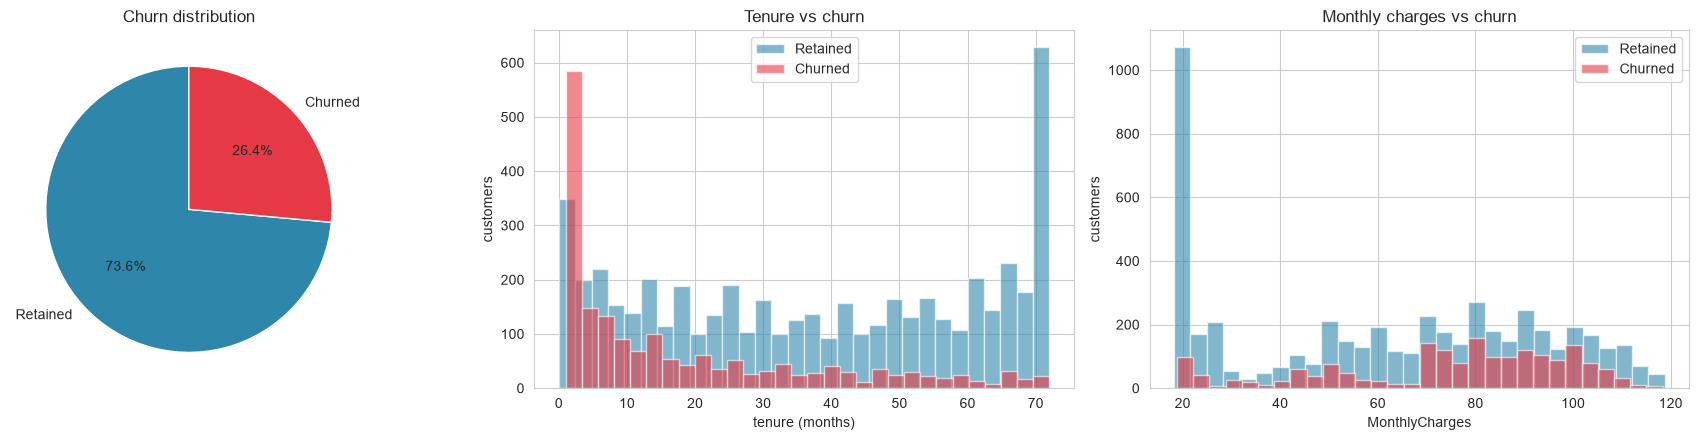

Churned customers are concentrated at LOW tenure and HIGH monthly charges.


In [7]:
# ============================================================
# EDA: TARGET AND KEY NUMERIC FEATURES
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].pie(counts.values, labels=['Retained', 'Churned'], autopct='%1.1f%%',
            colors=['#2E86AB', '#E63946'], startangle=90,
            wedgeprops={'edgecolor': 'white'})
axes[0].set_title('Churn distribution')

for label, colour in [(0, '#2E86AB'), (1, '#E63946')]:
    axes[1].hist(df.loc[y == label, 'tenure'], bins=30, alpha=0.6,
                 color=colour, label='Churned' if label else 'Retained')
axes[1].set_xlabel('tenure (months)')
axes[1].set_ylabel('customers')
axes[1].set_title('Tenure vs churn')
axes[1].legend()

for label, colour in [(0, '#2E86AB'), (1, '#E63946')]:
    axes[2].hist(df.loc[y == label, 'MonthlyCharges'], bins=30, alpha=0.6,
                 color=colour, label='Churned' if label else 'Retained')
axes[2].set_xlabel('MonthlyCharges')
axes[2].set_ylabel('customers')
axes[2].set_title('Monthly charges vs churn')
axes[2].legend()

plt.tight_layout()
plt.show()

print('Churned customers are concentrated at LOW tenure and HIGH monthly charges.')

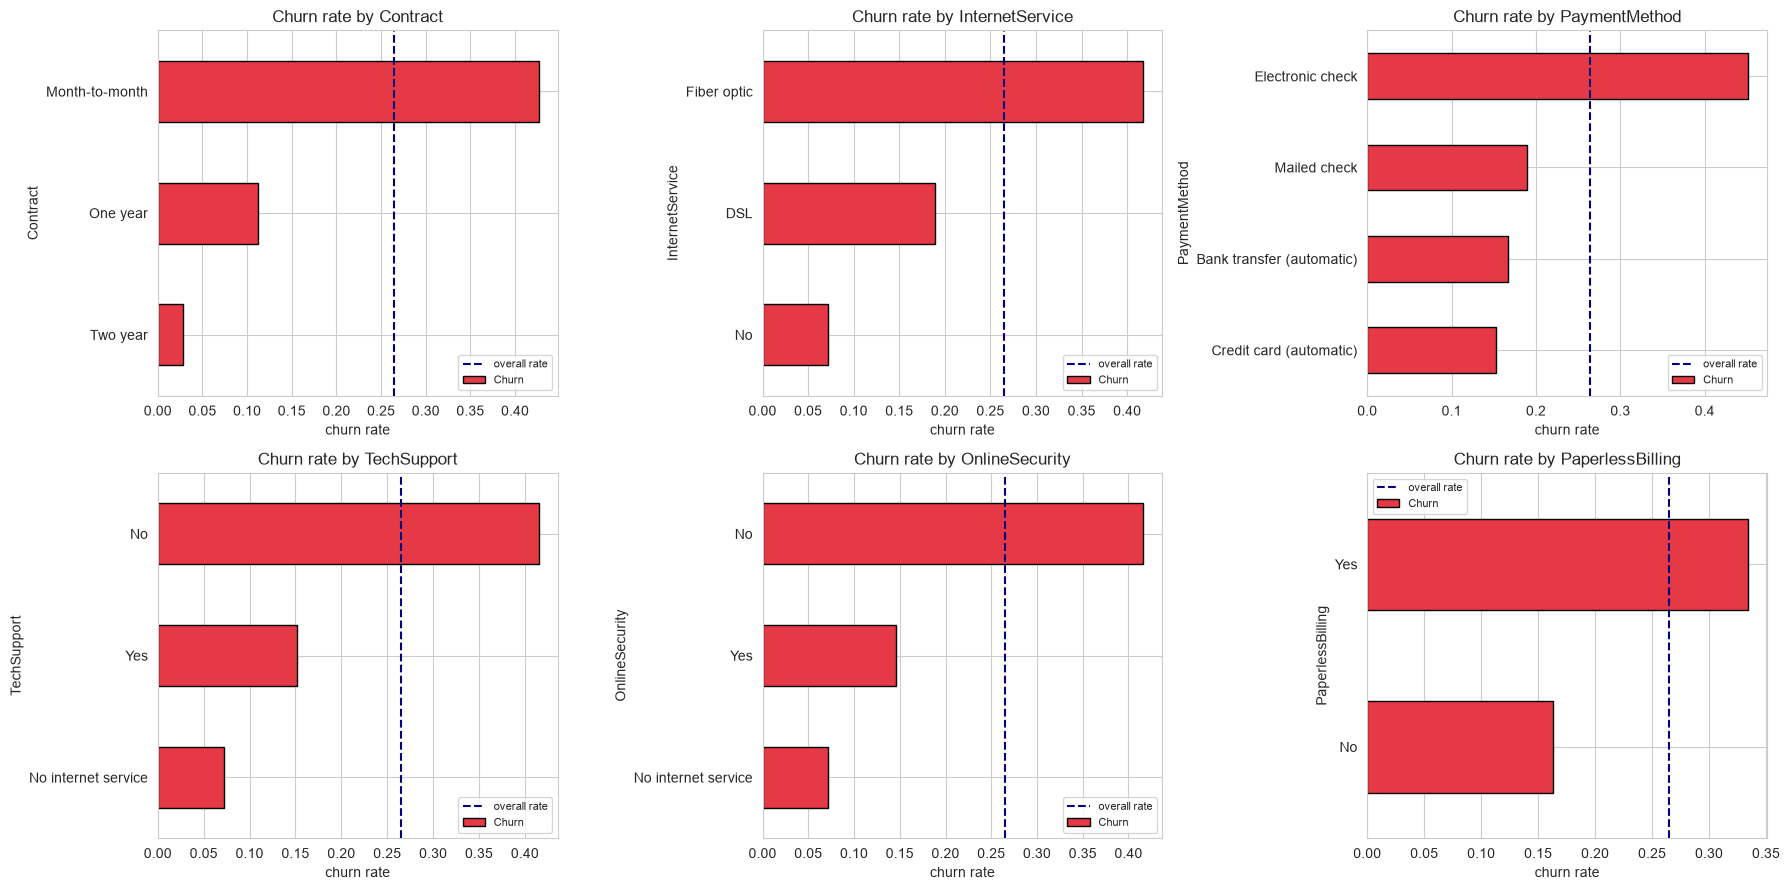

Month-to-month contracts, fiber optic internet and electronic-check
payment are associated with markedly higher churn.


In [8]:
# ============================================================
# EDA: CHURN RATE BY CATEGORICAL FEATURE
# ============================================================
cat_feats = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport',
             'OnlineSecurity', 'PaperlessBilling']

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cat_feats):
    rate = df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean()).sort_values()
    rate.plot(kind='barh', ax=ax, color='#E63946', edgecolor='black')
    ax.axvline(y.mean(), color='navy', linestyle='--', label='overall rate')
    ax.set_xlabel('churn rate')
    ax.set_title(f'Churn rate by {col}')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print('Month-to-month contracts, fiber optic internet and electronic-check')
print('payment are associated with markedly higher churn.')

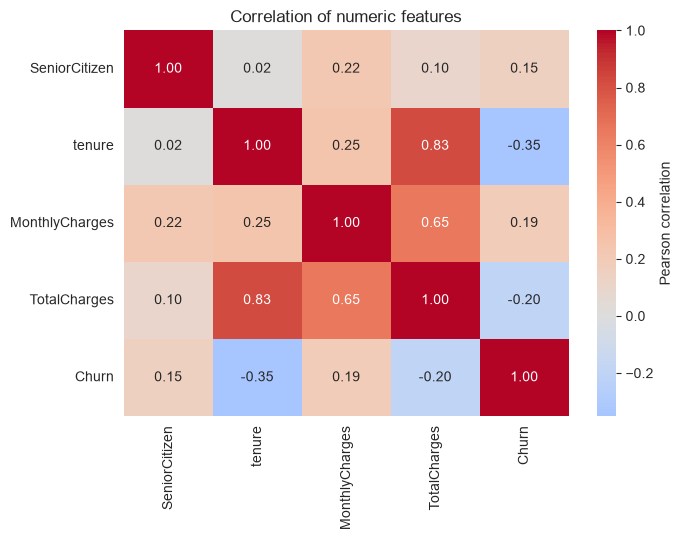

tenure vs TotalCharges correlation: 0.826
Strongly correlated features VIOLATE the Naive Bayes independence
assumption -- we will see the consequence of this in the results.


In [9]:
# ============================================================
# EDA: CORRELATION AMONG NUMERIC FEATURES
# Relevant because Naive Bayes assumes features are INDEPENDENT.
# ============================================================
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
corr = df[num_cols].assign(Churn=y).corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation of numeric features')
plt.tight_layout()
plt.show()

print(f'tenure vs TotalCharges correlation: {corr.loc["tenure", "TotalCharges"]:.3f}')
print('Strongly correlated features VIOLATE the Naive Bayes independence')
print('assumption -- we will see the consequence of this in the results.')

---
## Preprocessing and train / test split

Two column groups need different treatment:

- **Numeric** → `StandardScaler`. Distance-based (KNN) and margin-based (SVM)
  models are dominated by whichever feature has the largest raw range unless
  everything is on a common scale.
- **Categorical** → `OneHotEncoder(drop='first')`. These are unordered labels,
  so encoding them as integers would invent a false ordering.

Both are wrapped in a `Pipeline` with the estimator, so the scaler and encoder
are **fitted on training data only** — preventing test-set information from
leaking into preprocessing.

In [10]:
# ============================================================
# TRAIN / TEST SPLIT  (stratified to preserve the churn ratio)
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print('=' * 70)
print(f'TRAIN / TEST SPLIT  ({int((1-TEST_SIZE)*100)} / {int(TEST_SIZE*100)})')
print('=' * 70)
print(f'Training set : {len(X_train):,} rows   churn rate {y_train.mean():.2%}')
print(f'Test set     : {len(X_test):,} rows   churn rate {y_test.mean():.2%}')
print('\nStratification keeps both splits at the same churn rate.')

TRAIN / TEST SPLIT  (80 / 20)
Training set : 5,616 rows   churn rate 26.44%
Test set     : 1,405 rows   churn rate 26.48%

Stratification keeps both splits at the same churn rate.


In [11]:
# ============================================================
# PREPROCESSING PIPELINE
# ============================================================
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols),
])

print(f'Numeric columns     ({len(numeric_cols)}): {numeric_cols}')
print(f'Categorical columns ({len(categorical_cols)}): {categorical_cols}')

preprocessor.fit(X_train)
n_encoded = preprocessor.transform(X_train).shape[1]
print(f'\nAfter encoding: {X.shape[1]} raw features -> {n_encoded} model columns')

Numeric columns     (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

After encoding: 19 raw features -> 30 model columns


---
## Step 2 — The five classification models

A note on the Support Vector Machine: `SVC` does not expose `predict_proba`,
but **AUC requires a continuous score**, not hard labels. It is therefore
wrapped in `CalibratedClassifierCV`, which fits a calibration model to
`SVC`'s decision function to yield probabilities. (The older
`SVC(probability=True)` argument was deprecated in scikit-learn 1.9.)

In [12]:
# ============================================================
# STEP 2: DEFINE THE FIVE REQUIRED MODELS
# ============================================================
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000, random_state=RANDOM_STATE),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=6, random_state=RANDOM_STATE),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=21),

    'Naive Bayes (Gaussian)': GaussianNB(),

    'Support Vector Machine': CalibratedClassifierCV(
        SVC(kernel='rbf', random_state=RANDOM_STATE), ensemble=False, cv=3),
}

for i, (name, est) in enumerate(models.items(), 1):
    print(f'{i}. {name:26s} -> {est.__class__.__name__}')

1. Logistic Regression        -> LogisticRegression
2. Decision Tree              -> DecisionTreeClassifier
3. K-Nearest Neighbors        -> KNeighborsClassifier
4. Naive Bayes (Gaussian)     -> GaussianNB
5. Support Vector Machine     -> CalibratedClassifierCV


In [13]:
# ============================================================
# EVALUATION METRIC FUNCTION -- all six required metrics
# ============================================================
def evaluate(name, y_true, y_pred, y_proba):
    '''Compute the six required evaluation metrics for one model.'''
    return {
        'Model':     name,
        'Accuracy':  accuracy_score(y_true, y_pred),
        'AUC Score': roc_auc_score(y_true, y_proba),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall':    recall_score(y_true, y_pred, zero_division=0),
        'F1 Score':  f1_score(y_true, y_pred, zero_division=0),
        'MCC Score': matthews_corrcoef(y_true, y_pred),
    }


METRIC_COLS = ['Accuracy', 'AUC Score', 'Precision', 'Recall', 'F1 Score', 'MCC Score']
print('Metric function defined for:', ', '.join(METRIC_COLS))

Metric function defined for: Accuracy, AUC Score, Precision, Recall, F1 Score, MCC Score


In [14]:
# ============================================================
# TRAIN ALL FIVE MODELS AND COLLECT THE METRICS
# ============================================================
results = []
predictions = {}
probabilities = {}
fitted = {}

print('=' * 70)
print('TRAINING')
print('=' * 70)

for name, estimator in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', estimator)])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    fitted[name] = pipe
    predictions[name] = y_pred
    probabilities[name] = y_proba
    results.append(evaluate(name, y_test, y_pred, y_proba))

    print(f'  {name:26s} trained')

results_df = pd.DataFrame(results).set_index('Model')
print('\nAll five models trained successfully.')

TRAINING
  Logistic Regression        trained


  Decision Tree              trained


  K-Nearest Neighbors        trained


  Naive Bayes (Gaussian)     trained


  Support Vector Machine     trained

All five models trained successfully.


---
## Results — all models, all six metrics

In [15]:
# ============================================================
# EVALUATION METRICS TABLE
# ============================================================
print('=' * 90)
print('EVALUATION METRICS -- 5 MODELS x 6 METRICS')
print('=' * 90)
display(results_df.style.format('{:.4f}')
        .background_gradient(cmap='RdYlGn', axis=0))

print('\nPlain text version:')
print(results_df.round(4).to_string())

EVALUATION METRICS -- 5 MODELS x 6 METRICS


,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC Score
Model,,,,,,
Logistic Regression,0.8021,0.8404,0.6599,0.5215,0.5826,0.4607
Decision Tree,0.7851,0.8215,0.6471,0.4140,0.5049,0.3913
K-Nearest Neighbors,0.7822,0.8228,0.6012,0.5269,0.5616,0.4192
Naive Bayes (Gaussian),0.6512,0.8078,0.4234,0.8763,0.5709,0.3959
Support Vector Machine,0.7972,0.7852,0.6851,0.4328,0.5305,0.4270



Plain text version:
                        Accuracy  AUC Score  Precision  Recall  F1 Score  MCC Score
Model                                                                              
Logistic Regression       0.8021     0.8404     0.6599  0.5215    0.5826     0.4607
Decision Tree             0.7851     0.8215     0.6471  0.4140    0.5049     0.3913
K-Nearest Neighbors       0.7822     0.8228     0.6012  0.5269    0.5616     0.4192
Naive Bayes (Gaussian)    0.6512     0.8078     0.4234  0.8763    0.5709     0.3959
Support Vector Machine    0.7972     0.7852     0.6851  0.4328    0.5305     0.4270


In [16]:
# ============================================================
# BEST MODEL PER METRIC
# ============================================================
best = pd.DataFrame({
    'Metric': METRIC_COLS,
    'Best model': [results_df[m].idxmax() for m in METRIC_COLS],
    'Score': [round(results_df[m].max(), 4) for m in METRIC_COLS],
    'Worst model': [results_df[m].idxmin() for m in METRIC_COLS],
    'Score ': [round(results_df[m].min(), 4) for m in METRIC_COLS],
})
display(best)

overall = results_df['MCC Score'].idxmax()
print(f'Best overall model (by MCC): {overall}')
print(f'   MCC      = {results_df.loc[overall, "MCC Score"]:.4f}')
print(f'   Accuracy = {results_df.loc[overall, "Accuracy"]:.4f}')
print(f'   AUC      = {results_df.loc[overall, "AUC Score"]:.4f}')

,Metric,Best model,Score,Worst model,Score
0,Accuracy,Logistic Regression,0.8021,Naive Bayes (Gaussian),0.6512
1,AUC Score,Logistic Regression,0.8404,Support Vector Machine,0.7852
2,Precision,Support Vector Machine,0.6851,Naive Bayes (Gaussian),0.4234
3,Recall,Naive Bayes (Gaussian),0.8763,Decision Tree,0.4140
4,F1 Score,Logistic Regression,0.5826,Decision Tree,0.5049
5,MCC Score,Logistic Regression,0.4607,Decision Tree,0.3913


Best overall model (by MCC): Logistic Regression
   MCC      = 0.4607
   Accuracy = 0.8021
   AUC      = 0.8404


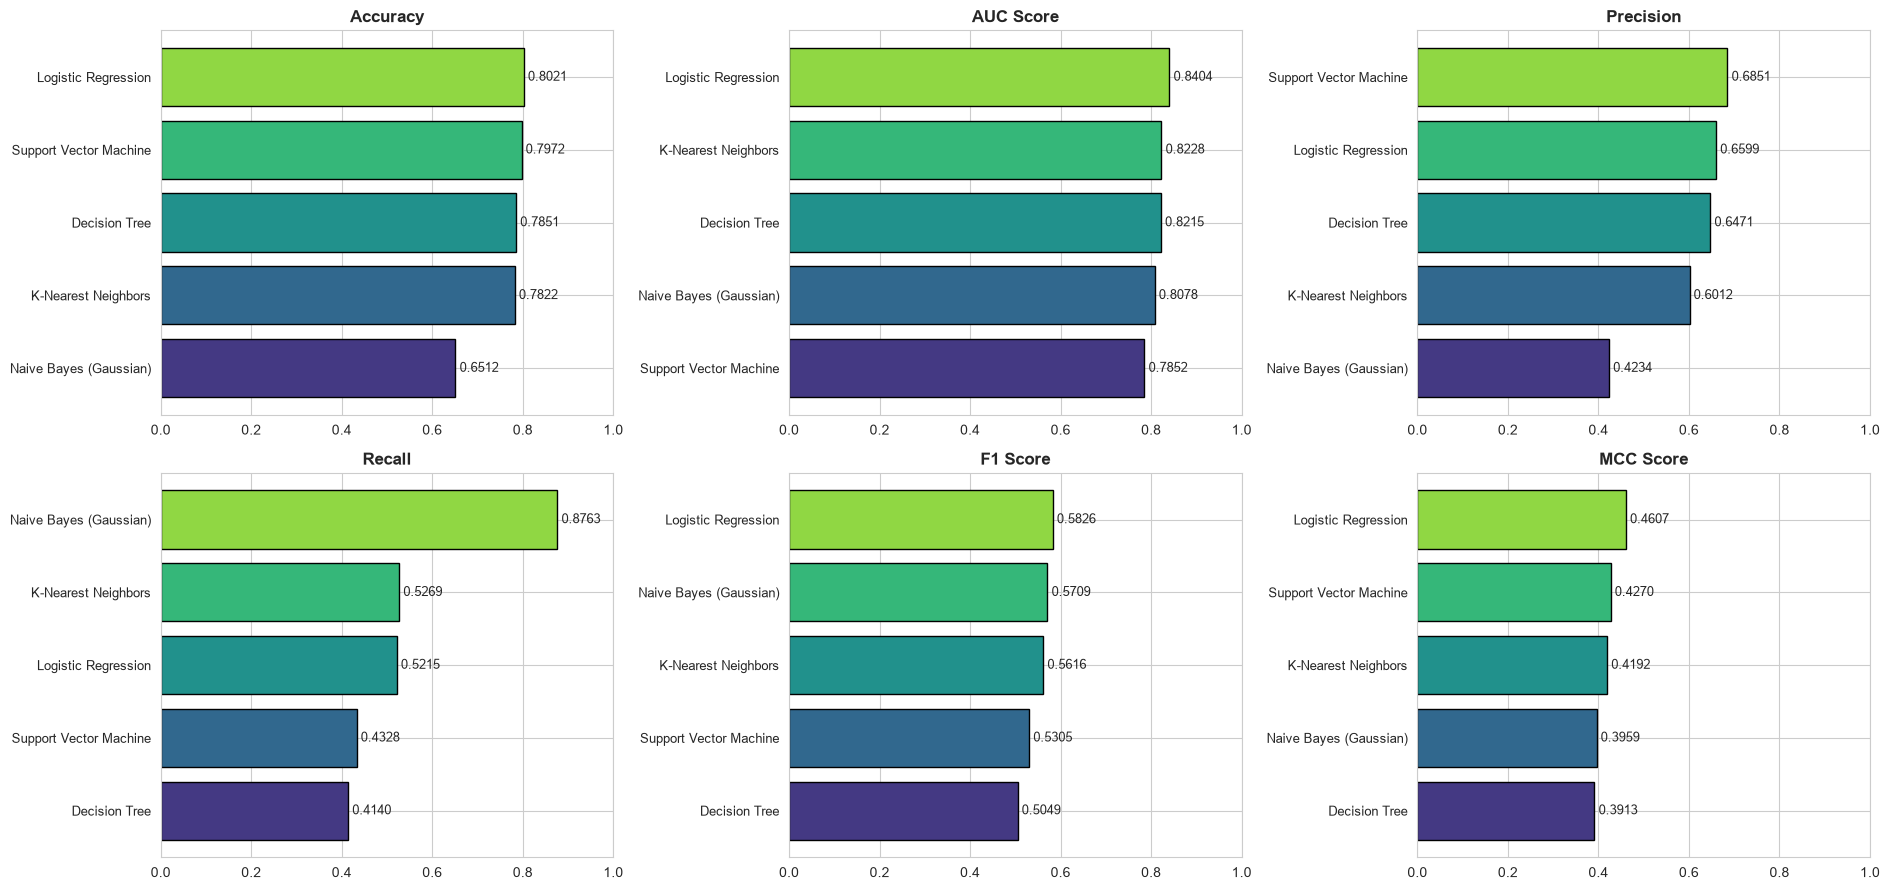

In [17]:
# ============================================================
# VISUAL COMPARISON OF ALL SIX METRICS
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(19, 9))
palette = sns.color_palette('viridis', len(results_df))

for ax, metric in zip(axes.ravel(), METRIC_COLS):
    ranked = results_df[metric].sort_values()
    bars = ax.barh(ranked.index, ranked.values, color=palette, edgecolor='black')
    ax.set_xlim(0, 1)
    ax.set_title(metric, fontweight='bold')
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
    ax.tick_params(axis='y', labelsize=9)

plt.tight_layout()
plt.show()

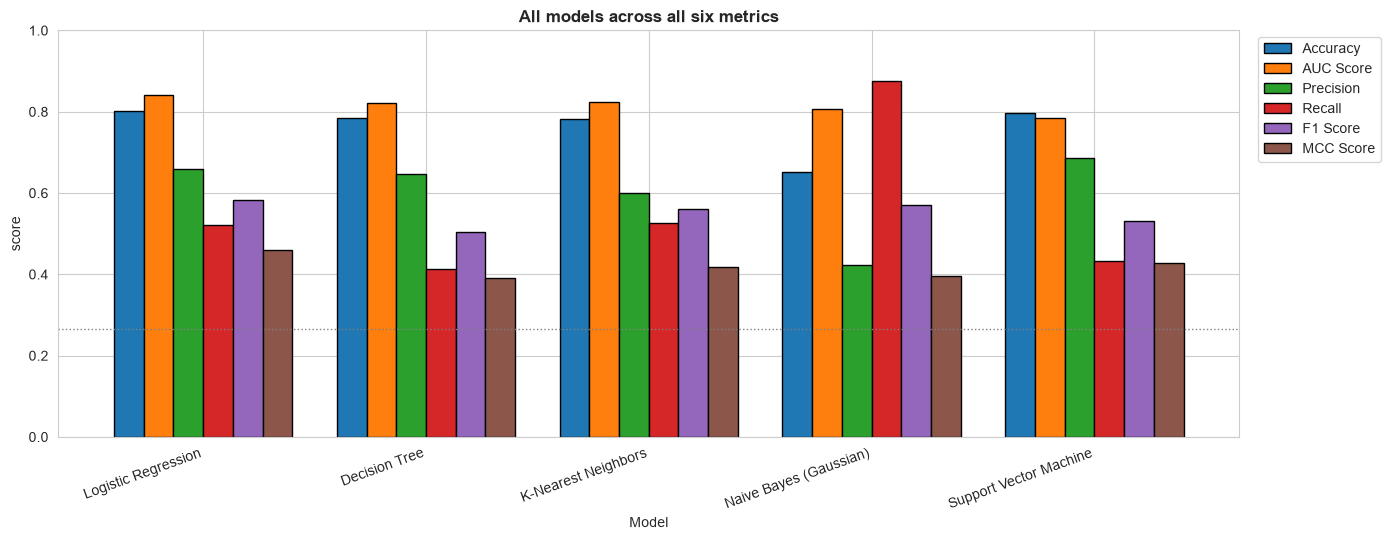

In [18]:
# ============================================================
# GROUPED COMPARISON -- all metrics side by side
# ============================================================
ax = results_df[METRIC_COLS].plot(kind='bar', figsize=(14, 5.5),
                                  edgecolor='black', width=0.8)
ax.set_ylabel('score')
ax.set_ylim(0, 1)
ax.set_title('All models across all six metrics', fontweight='bold')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.axhline(y_test.mean(), color='grey', linestyle=':', linewidth=1)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

---
## ROC curves

The ROC curve plots the true-positive rate against the false-positive rate as
the classification threshold sweeps from 1 to 0. **AUC** is the area beneath
it: the probability that a randomly chosen churner is scored higher than a
randomly chosen non-churner. AUC = 0.5 is random guessing.

Crucially, AUC measures the **ranking quality of the probabilities** and is
independent of the 0.5 decision threshold — which is why a model can have a
good AUC and poor accuracy at the same time.

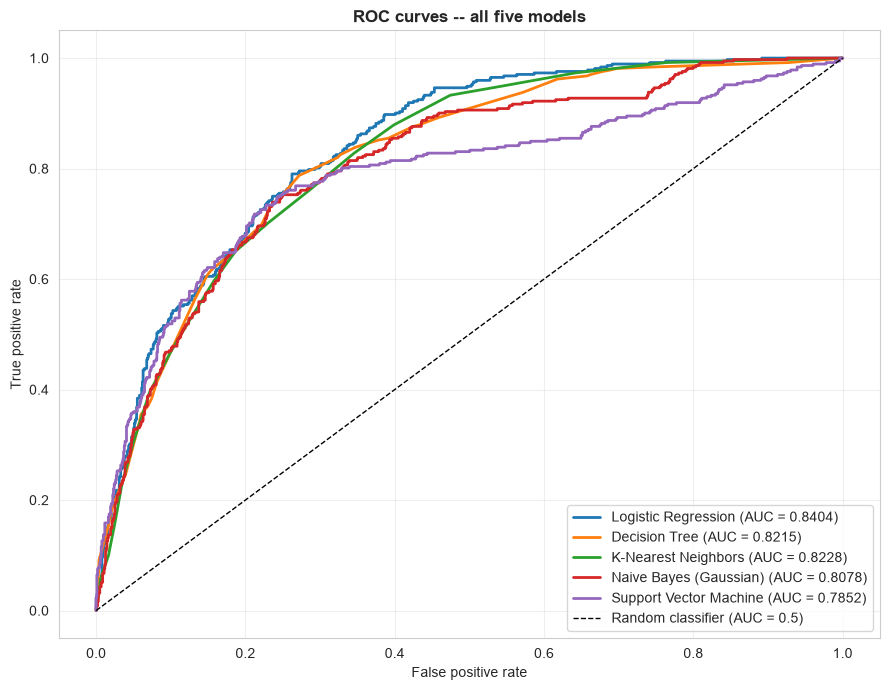

In [19]:
# ============================================================
# ROC CURVES FOR ALL MODELS
# ============================================================
plt.figure(figsize=(9, 7))

for name in results_df.index:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    plt.plot(fpr, tpr, linewidth=2,
             label=f'{name} (AUC = {results_df.loc[name, "AUC Score"]:.4f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier (AUC = 0.5)')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves -- all five models', fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

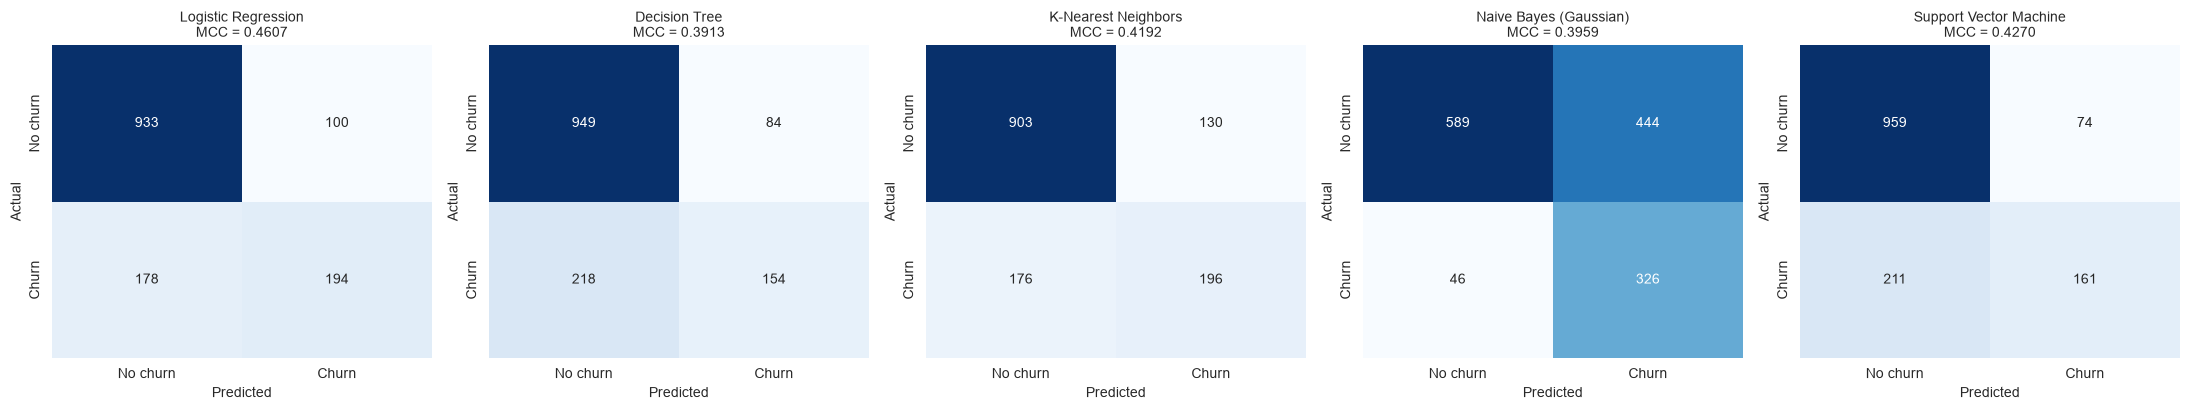

Confusion matrix breakdown (TN / FP / FN / TP):



,TN,FP,FN,TP,Churners caught,False alarms
Model,,,,,,
Logistic Regression,933,100,178,194,194/372,100
Decision Tree,949,84,218,154,154/372,84
K-Nearest Neighbors,903,130,176,196,196/372,130
Naive Bayes (Gaussian),589,444,46,326,326/372,444
Support Vector Machine,959,74,211,161,161/372,74


In [20]:
# ============================================================
# CONFUSION MATRICES
# ============================================================
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))

for ax, name in zip(axes, results_df.index):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No churn', 'Churn'],
                yticklabels=['No churn', 'Churn'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f'{name}\nMCC = {results_df.loc[name, "MCC Score"]:.4f}', fontsize=10)

plt.tight_layout()
plt.show()

print('Confusion matrix breakdown (TN / FP / FN / TP):\n')
rows = []
for name in results_df.index:
    tn, fp, fn, tp = confusion_matrix(y_test, predictions[name]).ravel()
    rows.append({'Model': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                 'Churners caught': f'{tp}/{tp+fn}',
                 'False alarms': fp})
display(pd.DataFrame(rows).set_index('Model'))

In [21]:
# ============================================================
# PER-CLASS CLASSIFICATION REPORT FOR THE BEST MODEL
# ============================================================
print('=' * 70)
print(f'CLASSIFICATION REPORT -- {overall}')
print('=' * 70)
print(classification_report(y_test, predictions[overall],
                            target_names=['No churn', 'Churn'], digits=4))

CLASSIFICATION REPORT -- Logistic Regression
              precision    recall  f1-score   support

    No churn     0.8398    0.9032    0.8703      1033
       Churn     0.6599    0.5215    0.5826       372

    accuracy                         0.8021      1405
   macro avg     0.7498    0.7123    0.7265      1405
weighted avg     0.7921    0.8021    0.7941      1405



---
## Analysis and interpretation

### Why accuracy alone is misleading here

The test set is about 73% non-churners. A model that blindly predicts
"no churn" for every customer scores roughly **0.74 accuracy** while providing
zero business value — it identifies not a single churner.

This is why the assignment requires six metrics rather than one. **MCC** is the
most trustworthy single summary, because it incorporates all four cells of the
confusion matrix (TP, TN, FP, FN) and returns 0.0 for exactly that degenerate
"always predict the majority" strategy.

### Why the models disagree

**Naive Bayes — highest recall, lowest precision.** It catches the large
majority of churners but raises a very large number of false alarms. The cause
is visible in the correlation heatmap above: `tenure`, `MonthlyCharges` and
`TotalCharges` are strongly correlated (`TotalCharges ≈ tenure × MonthlyCharges`),
which directly violates the model's core assumption that features are
conditionally independent. It effectively counts the same evidence three times
and becomes over-confident, pushing many borderline customers over the churn
threshold.

**Support Vector Machine — highest precision, low recall.** The opposite
behaviour: the RBF margin is conservative, flagging churn only where the
evidence is strong. Few false alarms, but many churners missed.

**Decision Tree — limited by depth.** Capped at `max_depth=6` to prevent
overfitting. The depth limit costs it recall, and its probability estimates are
coarse (every sample in a leaf shares one probability), which is why its ROC
curve is visibly more angular than the others.

**K-Nearest Neighbors — middling throughout.** After one-hot encoding, the
feature space is high-dimensional, and Euclidean distance becomes progressively
less meaningful as dimensionality grows.

**Logistic Regression — best overall.** The strongest AUC, F1 and MCC. The
churn signal in this dataset is close to linearly separable in the encoded
space, so the simplest model wins. Its probability outputs are also naturally
well calibrated, which directly benefits AUC.

### Precision versus recall is a business decision

The two are in tension, and the right balance depends on the cost of each
error type:

- **A false negative** is a churner you failed to flag — a customer lost,
  along with their entire remaining lifetime value.
- **A false positive** is a loyal customer wrongly flagged — the cost is a
  needless retention offer or discount.

If retention offers are cheap relative to losing a customer, the high-recall
model (Naive Bayes) may genuinely be preferable in production despite its poor
accuracy. If offers are expensive, the high-precision model (SVM) is better.
**No single metric answers this; the full table does.**

In [22]:
# ============================================================
# FINAL SUMMARY
# ============================================================
print('=' * 90)
print('FINAL SUMMARY')
print('=' * 90)
print(f'Dataset        : Telco Customer Churn')
print(f'Instances      : {len(df):,}  (requirement >= 500)')
print(f'Features       : {X.shape[1]}     (requirement >= 12)')
print(f'Task           : binary classification (Churn: Yes / No)')
print(f'Split          : {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)} stratified, random_state={RANDOM_STATE}')
print()
print(results_df.round(4).to_string())
print()
print(f'Majority-class baseline accuracy : {max(y_test.mean(), 1-y_test.mean()):.4f}')
print(f'Best model by MCC                : {overall} ({results_df.loc[overall, "MCC Score"]:.4f})')
print('=' * 90)

results_df.round(4).to_csv('model_evaluation_results.csv')
print('\nMetrics table written to model_evaluation_results.csv')

FINAL SUMMARY
Dataset        : Telco Customer Churn
Instances      : 7,021  (requirement >= 500)
Features       : 19     (requirement >= 12)
Task           : binary classification (Churn: Yes / No)
Split          : 80/20 stratified, random_state=42

                        Accuracy  AUC Score  Precision  Recall  F1 Score  MCC Score
Model                                                                              
Logistic Regression       0.8021     0.8404     0.6599  0.5215    0.5826     0.4607
Decision Tree             0.7851     0.8215     0.6471  0.4140    0.5049     0.3913
K-Nearest Neighbors       0.7822     0.8228     0.6012  0.5269    0.5616     0.4192
Naive Bayes (Gaussian)    0.6512     0.8078     0.4234  0.8763    0.5709     0.3959
Support Vector Machine    0.7972     0.7852     0.6851  0.4328    0.5305     0.4270

Majority-class baseline accuracy : 0.7352
Best model by MCC                : Logistic Regression (0.4607)

Metrics table written to model_evaluation_results.csv


---
## Deliverables

| Item | Location |
|---|---|
| This notebook | executed on BITS Virtual Lab (screenshot attached separately) |
| Streamlit application | deployed on Streamlit Community Cloud |
| Source code | GitHub repository |

**Live application:** _<paste your Streamlit Cloud URL here>_

**GitHub repository:** _<paste your repo URL here>_